<a href="https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda_dependence.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Spatial distribution and spatial dependence of poverty in Bolivia

Part of the [GeoDevelopment Observatory of Bolivia](https://quarcs-lab.github.io/geo4bolivia/).

How is multidimensional poverty spread across Bolivia's 339 municipalities, and how much does a municipality resemble its neighbours? This notebook uses the Multidimensional Poverty Index (MPI, 2012; higher = poorer) from the `geo4bolivia` package:

1. **Load the data** with `geo4bolivia`
2. **Spatial distribution**: two ways of classifying a map, box-plot breaks and Fisher-Jenks natural breaks
3. **Spatial dependence**: spatial weights, the spatial lag, global Moran's I and local clusters and outliers (LISA)

## 0. Setup

In Google Colab the next cell installs the package and the spatial-analysis libraries (a few seconds). Locally, `uv sync` has installed them already.

In [1]:
import importlib.util

missing = [p for p in ["geo4bolivia", "mapclassify", "libpysal", "esda", "splot"] if importlib.util.find_spec(p) is None]
if missing:
    pkgs = " ".join(missing)
    !pip install -q {pkgs}

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mapclassify as mc

from libpysal import weights
from esda.moran import Moran, Moran_Local
from splot.esda import moran_scatterplot, lisa_cluster
from splot.libpysal import plot_spatial_weights

import geo4bolivia as geo

warnings.filterwarnings("ignore", message="Numba not installed")   # mapclassify works without it
sns.set_theme(style="whitegrid")
SEED = 12345

## 1. Load the data

The MPI with municipal boundaries and names, plus the department of each municipality. The map is projected to the observatory's equal-area projection.

In [3]:
INDICATOR = "sdg1_2_mpi"           # Multidimensional Poverty Index, 2012 (0-1, higher = poorer)
LABEL = "Multidimensional poverty index (2012)"

gdf = geo.load("sdg", variables=INDICATOR, years=2012, geometry=True)
units = geo.units("municipality")[["geo_id", "department_id"]]
gdf = gdf.merge(units, on="geo_id")
gdf["department"] = gdf["department_id"].map(geo.units("department").set_index("geo_id")["name"])
gdf = gdf[["geo_id", "name", "department", INDICATOR, "geometry"]].to_crs(geo.config()["equal_area_crs"])

departments = geo.boundaries("department").to_crs(gdf.crs)
gdf.head()

,geo_id,name,department,sdg1_2_mpi,geometry
0,BO-01-01-01,Azurduy,Chuquisaca,0.440,"MULTIPOLYGON (((19837.994 -373037.131, 19167.6..."
1,BO-01-01-02,Tarvita,Chuquisaca,0.380,"MULTIPOLYGON (((9005.695 -368827.7, 8733.724 -..."
2,BO-01-02-01,Villa Serrano,Chuquisaca,0.199,"MULTIPOLYGON (((2196.498 -264540.426, 1902.277..."
3,BO-01-03-01,Huacareta,Chuquisaca,0.261,"MULTIPOLYGON (((35328.625 -486868.048, 34642.8..."
4,BO-01-03-02,Monteagudo,Chuquisaca,0.166,"MULTIPOLYGON (((21748.339 -439187.098, 22030.2..."


## 2. Spatial distribution

How we cut a continuous variable into classes changes what a map shows. Two classifications from `mapclassify`:

### Box-plot breaks

Box-plot breaks follow the box plot: the classes are the quartiles, and values beyond 1.5 times the interquartile range from the box are flagged as outliers.

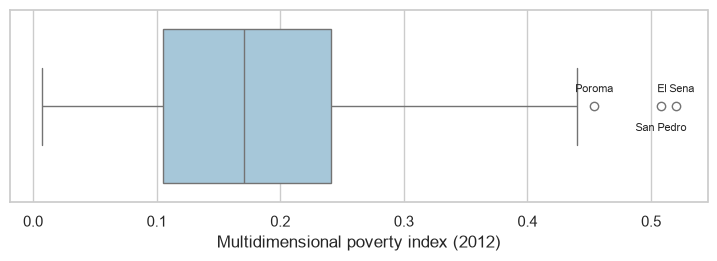

In [4]:
fig, ax = plt.subplots(figsize=(9, 2.5))
sns.boxplot(x=gdf[INDICATOR], color="#9ecae1", ax=ax)
for i, (_, row) in enumerate(gdf.nlargest(3, INDICATOR).iterrows()):   # label the three outliers
    ax.annotate(row["name"], (row[INDICATOR], 0), xytext=(0, 10 if i % 2 == 0 else -18), textcoords="offset points",
                ha="center", fontsize=8)
ax.set(xlabel=LABEL)
plt.show()

In [5]:
mc.BoxPlot(gdf[INDICATOR])

BoxPlot

   Interval      Count
----------------------
( -inf, -0.10] |     0
(-0.10,  0.10] |    85
( 0.10,  0.17] |    87
( 0.17,  0.24] |    83
( 0.24,  0.45] |    81
( 0.45,  0.52] |     3

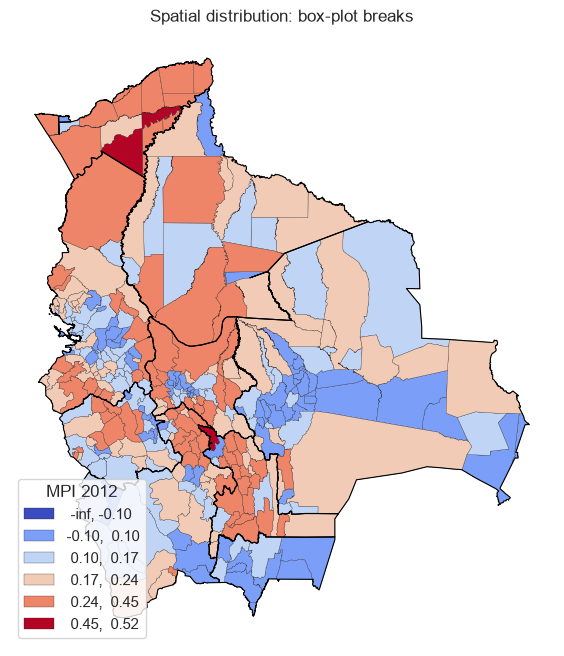

In [6]:
fig, ax = plt.subplots(figsize=(9, 8))
gdf.plot(column=INDICATOR, scheme="BoxPlot", cmap="coolwarm", edgecolor="k", linewidth=0.2, legend=True,
         legend_kwds={"title": "MPI 2012", "loc": "lower left"}, ax=ax)
departments.boundary.plot(ax=ax, color="black", linewidth=0.8)
ax.set_title("Spatial distribution: box-plot breaks")
ax.set_axis_off()
plt.show()

The median MPI is 0.17, and the middle half of the municipalities lies between 0.10 and 0.24. The lower whisker would extend below zero, so no municipality is a low outlier (the first class is empty), while three are high outliers above 0.45: El Sena and San Pedro in Pando and Poroma in Chuquisaca. On the map, the upper quartile (0.24 to 0.45) covers most of Pando, western Beni, the highlands of La Paz and the valleys where Cochabamba, Potosí and Chuquisaca meet; the lower quartile covers the main cities, the Santa Cruz lowlands and Tarija.

### Fisher-Jenks breaks

The Fisher-Jenks algorithm chooses breaks that make classes as homogeneous as possible (it minimises the variance within classes). Here, three classes:

In [7]:
mc.FisherJenks(gdf[INDICATOR], k=3)

FisherJenks

  Interval     Count
--------------------
[0.01, 0.15] |   146
(0.15, 0.28] |   148
(0.28, 0.52] |    45

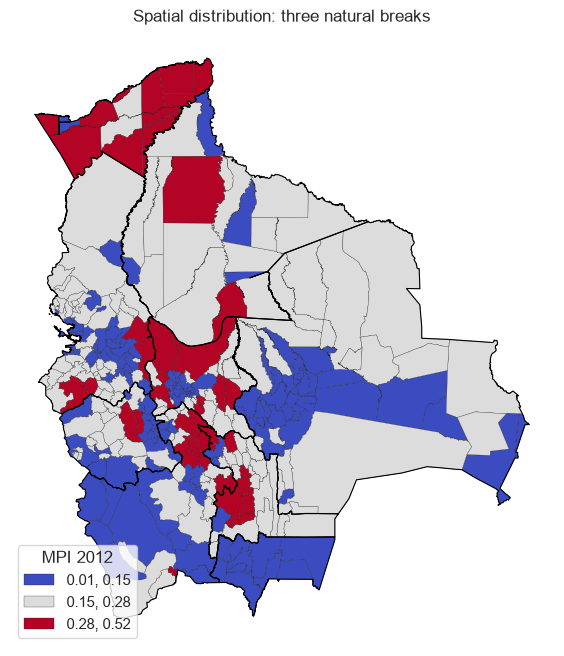

In [8]:
fig, ax = plt.subplots(figsize=(9, 8))
gdf.plot(column=INDICATOR, scheme="FisherJenks", k=3, cmap="coolwarm", edgecolor="k", linewidth=0.2, legend=True,
         legend_kwds={"title": "MPI 2012", "loc": "lower left"}, ax=ax)
departments.boundary.plot(ax=ax, color="black", linewidth=0.8)
ax.set_title("Spatial distribution: three natural breaks")
ax.set_axis_off()
plt.show()

Natural breaks put 146 municipalities in the low class (up to 0.15), 148 in the middle class (0.15 to 0.28) and 45 in the high class (above 0.28). Where box-plot breaks give each quartile about 85 municipalities, natural breaks single out a smaller group of very poor municipalities, which shows the poverty belt across Chuquisaca, Potosí and Cochabamba and the cluster in Pando more sharply.

## 3. Spatial dependence

- To what extent is the poverty of a municipality similar to that of its neighbours?
- To what extent is there an overall pattern of clustering?
- Where are the statistically significant spatial clusters?
- Where are the statistically significant spatial outliers?

### Spatial connectivity

Each municipality is connected to its 6 nearest neighbours; the weights are row-standardised, so each neighbour counts 1/6.

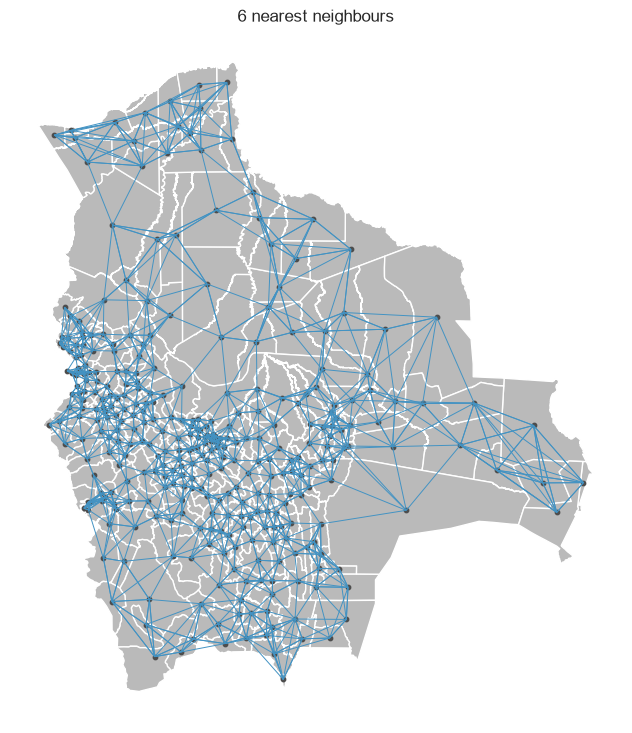

In [9]:
W = weights.KNN.from_dataframe(gdf, k=6)
W.transform = "r"

fig, ax = plt.subplots(figsize=(9, 9))
plot_spatial_weights(W, gdf, ax=ax)
ax.set_title("6 nearest neighbours")
plt.show()

### Global dependence

The spatial lag is the average poverty of the neighbours. Its relationship with each municipality's own poverty is the Moran scatterplot:

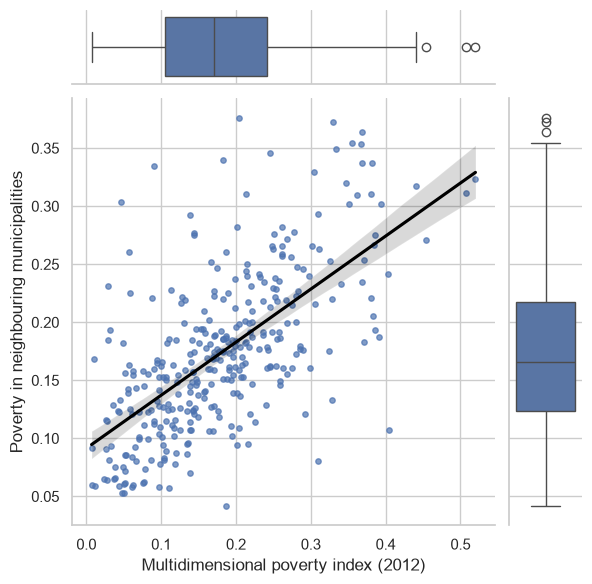

In [10]:
gdf["W_mpi"] = weights.lag_spatial(W, gdf[INDICATOR])

g = sns.JointGrid(data=gdf, x=INDICATOR, y="W_mpi", height=6)
g.plot_joint(sns.regplot, scatter_kws={"s": 15, "alpha": 0.7}, line_kws={"color": "black"})
g.plot_marginals(sns.boxplot)
g.set_axis_labels(LABEL, "Poverty in neighbouring municipalities")
plt.show()

In [11]:
np.random.seed(SEED)
globalMoran = Moran(gdf[INDICATOR], W, permutations=999)
MoranI = f"{globalMoran.I:.2f}"
slope = np.polyfit(gdf[INDICATOR], gdf["W_mpi"], 1)[0]

print(f"Moran's I = {globalMoran.I:.3f}, pseudo p-value = {globalMoran.p_sim:.3f} (999 permutations)")
print(f"Slope of the scatterplot above: {slope:.3f}")

Moran's I = 0.457, pseudo p-value = 0.001 (999 permutations)
Slope of the scatterplot above: 0.457


Moran's I is 0.46 with a pseudo p-value of 0.001, the smallest possible with 999 permutations: no random reshuffle of the values across the map produced as much clustering. With row-standardised weights, Moran's I is exactly the slope of the scatterplot above (0.457). A municipality whose MPI is 0.1 above the mean has neighbours whose average MPI is, on average, about 0.046 above the mean.

### Local dependence

Local Moran's I tests, municipality by municipality, whether its value and its neighbours' are more alike (clusters) or more different (outliers) than a random arrangement would give. Here we use a 10% significance level.

In [12]:
localMoran = Moran_Local(gdf[INDICATOR], W, permutations=999, seed=SEED)

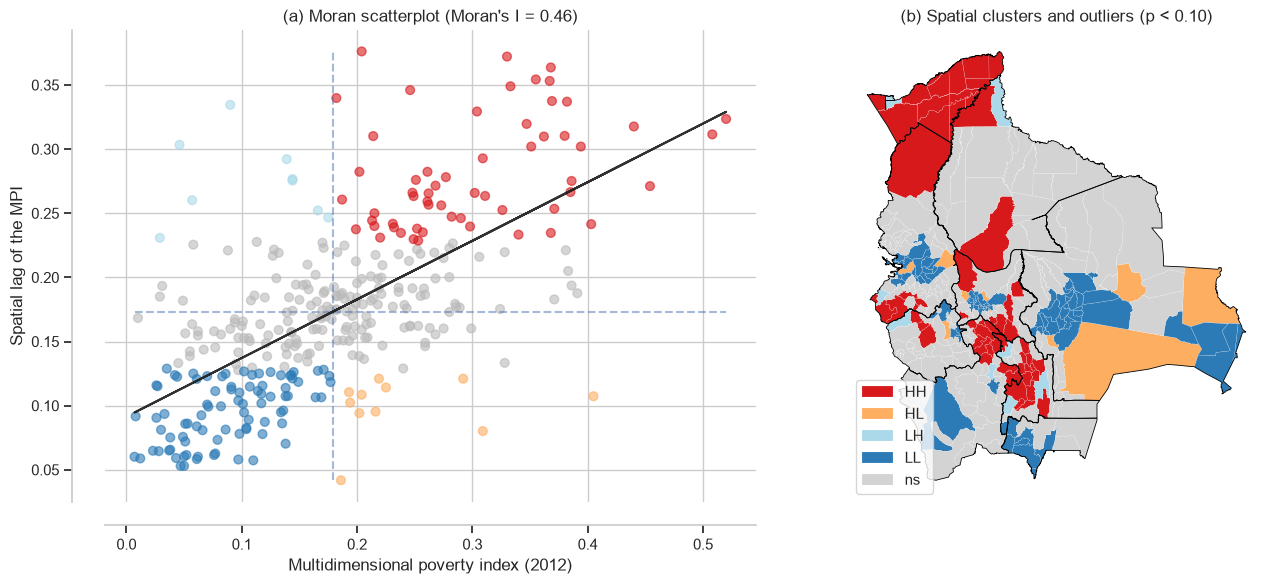

In [13]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))

moran_scatterplot(localMoran, p=0.10, aspect_equal=False, zstandard=False, ax=axes[0])
lisa_cluster(localMoran, gdf, p=0.10, legend_kwds={"loc": "lower left"}, ax=axes[1])
departments.boundary.plot(ax=axes[1], color="black", linewidth=0.6)

axes[0].set_xlabel(LABEL)
axes[0].set_ylabel("Spatial lag of the MPI")
axes[0].set_title(f"(a) Moran scatterplot (Moran's I = {MoranI})")
axes[1].set_title("(b) Spatial clusters and outliers (p < 0.10)")
plt.tight_layout()
plt.show()

How many municipalities fall in each group, at the 10% and at the stricter 5% level?

In [14]:
quadrants = {1: "High-high", 2: "Low-high", 3: "Low-low", 4: "High-low"}
groups = pd.Series(localMoran.q).map(quadrants)
pd.DataFrame({f"p < {p:.2f}": groups.where(localMoran.p_sim < p, "Not significant").value_counts()
              for p in (0.10, 0.05)})

,p < 0.10,p < 0.05
Not significant,175,216
Low-low,86,64
High-high,58,43
High-low,11,9
Low-high,9,7


In [15]:
gdf["cluster"] = groups.where(localMoran.p_sim < 0.10, "Not significant").values
pd.crosstab(gdf["department"], gdf["cluster"], margins=True, margins_name="Total")

cluster,High-high,High-low,Low-high,Low-low,Not significant,Total
department,,,,,,
Beni,2,0,1,0,16,19
Chuquisaca,15,0,3,1,10,29
Cochabamba,7,3,0,19,18,47
La Paz,7,3,1,23,53,87
Oruro,3,1,1,4,26,35
Pando,13,0,2,0,0,15
Potosí,11,0,1,2,26,40
Santa Cruz,0,4,0,30,22,56
Tarija,0,0,0,7,4,11


At the 10% level, 164 municipalities belong to a significant group, 41 more than at 5%:

- **58 poverty hotspots (High-high)**: all of Pando except Cobija and Porvenir (13 of 15), 15 in Chuquisaca, 11 in Potosí and 7 each in Cochabamba and La Paz.
- **86 clusters of low poverty (Low-low)**: 30 in Santa Cruz, 23 in La Paz, 19 in Cochabamba and 7 of Tarija's 11 municipalities.
- **20 outliers**: 11 poorer municipalities with less poor neighbours (High-low) and 9 less poor municipalities with poorer neighbours (Low-high).

A looser threshold flags more municipalities but also more false positives: with 339 tests at 10%, about 34 would be significant by chance even with no spatial pattern at all. The core clusters are the same at both levels.

## Summary

- The MPI (2012) has a median of 0.17 and a long upper tail; box-plot breaks flag three high outliers (El Sena, San Pedro, Poroma), and three Fisher-Jenks classes isolate 45 very poor municipalities above 0.28.
- Poverty is strongly spatially dependent: Moran's I = 0.46 (pseudo p-value 0.001) with 6-nearest-neighbour weights.
- At the 10% level, LISA finds 58 poverty hotspots (Pando, Chuquisaca, Potosí) and 86 clusters of low poverty (Santa Cruz, La Paz, Cochabamba, Tarija).
- The companion notebook [`esda`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda.ipynb) lists the clusters and outliers at the 5% level.